In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold


## 1. Data Loading

In [60]:
df = pd.read_csv('Adult Census Income(Target column income).csv')

## 1. Data Understanding

In [61]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


| Column         | Description                                               |
| -------------- | --------------------------------------------------------- |
| age            | عمر الشخص بالسنوات.                                       |
| workclass      | نوع جهة العمل أو قطاع العمل.                              |
| fnlwgt         | وزن إحصائي يوضح عدد الأشخاص الذين يمثلهم السجل.           |
| education      | المستوى التعليمي الذي وصل إليه الشخص.                     |
| education.num  | تمثيل رقمي للمستوى التعليمي.                              |
| marital.status | الحالة الاجتماعية للشخص.                                  |
| occupation     | المهنة أو الوظيفة التي يعمل بها الشخص.                    |
| relationship   | علاقة الشخص بأفراد أسرته.                                 |
| race           | العِرق المسجل للشخص.                                      |
| sex            | جنس الشخص (ذكر أو أنثى).                                  |
| capital.gain   | الأرباح الناتجة عن بيع الأصول أو الاستثمارات.             |
| capital.loss   | الخسائر الناتجة عن بيع الأصول أو الاستثمارات.             |
| hours.per.week | عدد ساعات العمل أسبوعيًا.                                 |
| native.country | البلد الأصلي للشخص.                                       |
| income         | فئة دخل الشخص (أقل من أو يساوي 50 ألف أو أكبر من 50 ألف). |

In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.5 MB


In [63]:
df.shape

(32561, 15)

In [64]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [65]:
df.dtypes

age               int64
workclass           str
fnlwgt            int64
education           str
education.num     int64
marital.status      str
occupation          str
relationship        str
race                str
sex                 str
capital.gain      int64
capital.loss      int64
hours.per.week    int64
native.country      str
income              str
dtype: object

In [66]:
df['income'].value_counts()

income
<=50K    24720
>50K      7841
Name: count, dtype: int64

In [67]:
df['income'].value_counts(normalize=True) * 100

income
<=50K    75.919044
>50K     24.080956
Name: proportion, dtype: float64

In [68]:
df.isnull().sum().sort_values(ascending=False)

occupation        1843
workclass         1836
native.country     583
fnlwgt               0
education            0
education.num        0
age                  0
marital.status       0
relationship         0
sex                  0
race                 0
capital.gain         0
capital.loss         0
hours.per.week       0
income               0
dtype: int64

In [69]:
df.duplicated().sum()

np.int64(24)

### EDA

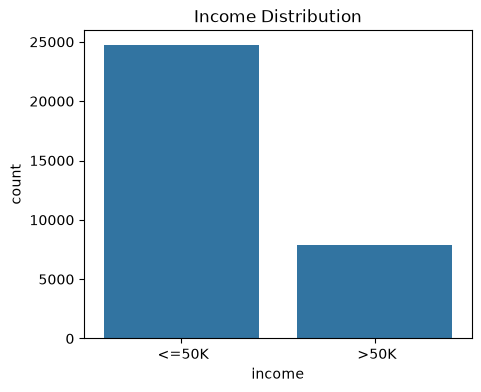

In [70]:
plt.figure(figsize=(5,4))
sns.countplot(x="income", data=df)
plt.title("Income Distribution")
plt.show()

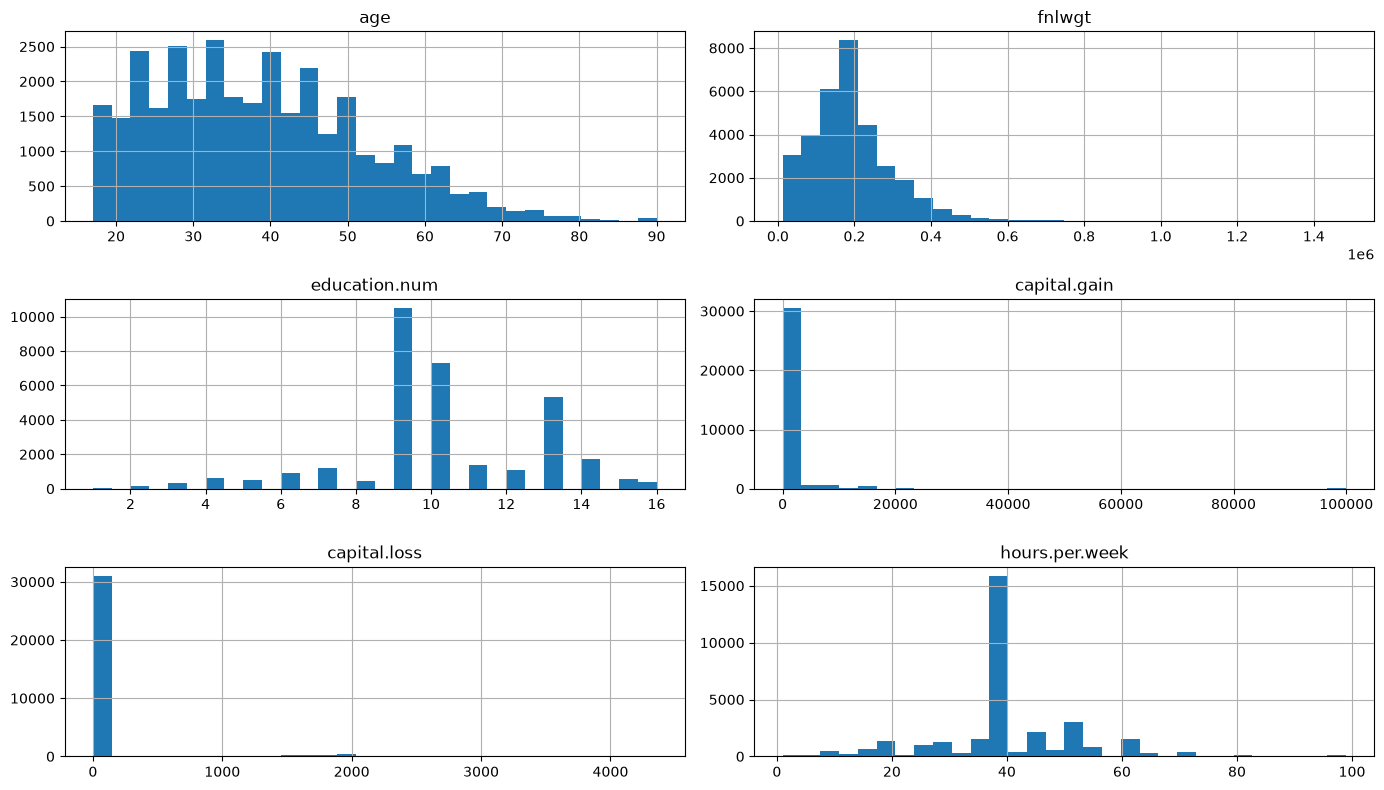

In [71]:
num_cols = ["age", "fnlwgt", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
df[num_cols].hist(bins=30, figsize=(14,8))
plt.tight_layout()
plt.show()

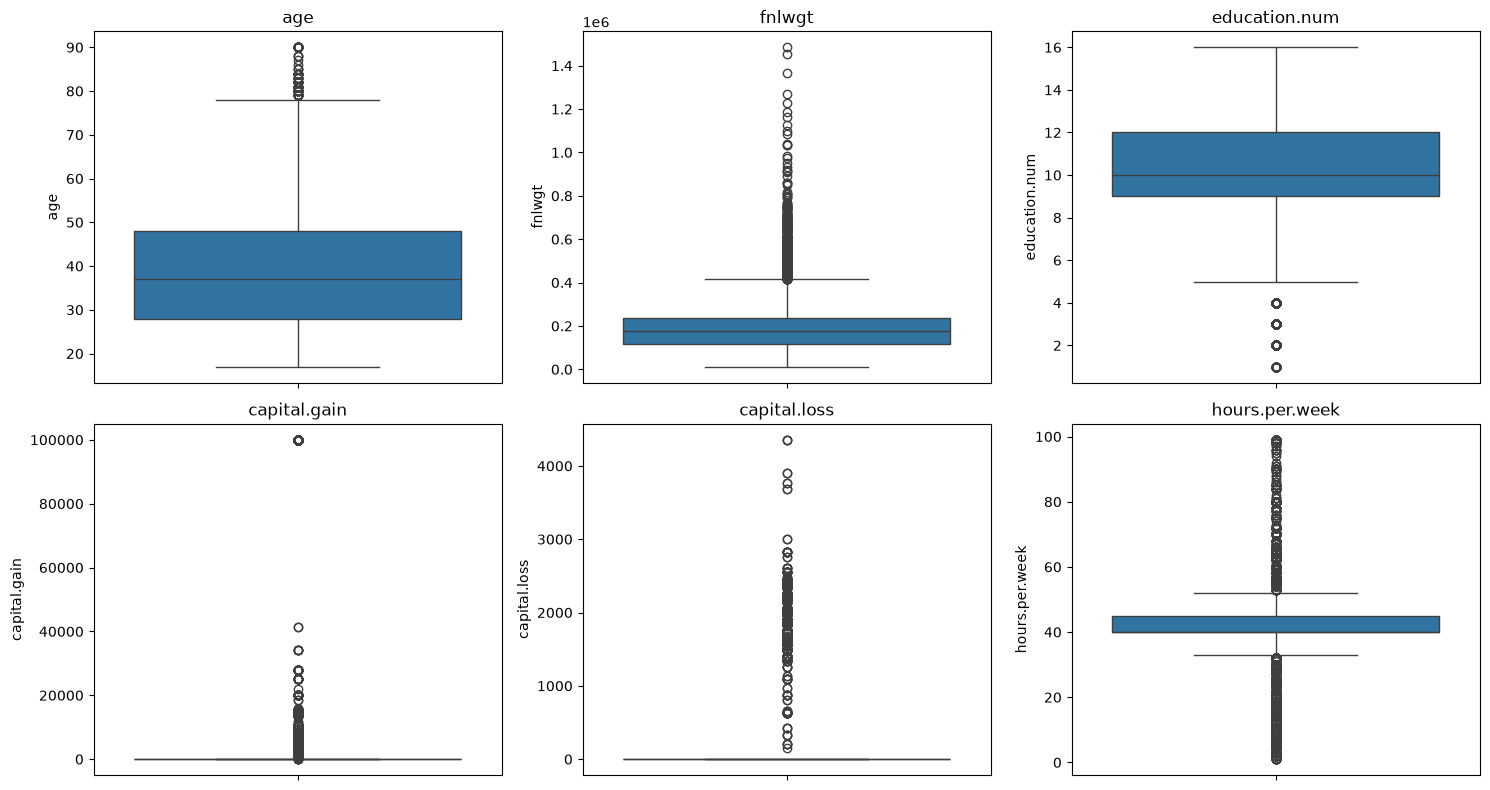

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15,8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [15]:
for col in num_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col:15s} -> {n} outliers ({n/len(df)*100:.1f}%)")

age             -> 143 outliers (0.4%)
fnlwgt          -> 992 outliers (3.0%)
education.num   -> 1198 outliers (3.7%)
capital.gain    -> 2712 outliers (8.3%)
capital.loss    -> 1519 outliers (4.7%)
hours.per.week  -> 9008 outliers (27.7%)


In [17]:
print("capital.gain max:", df["capital.gain"].max())
print("Rows with capital.gain = 99999:", (df["capital.gain"] == 99999).sum())
print("Rows with capital.gain > 0:", (df["capital.gain"] > 0).sum())

capital.gain max: 99999
Rows with capital.gain = 99999: 159
Rows with capital.gain > 0: 2712


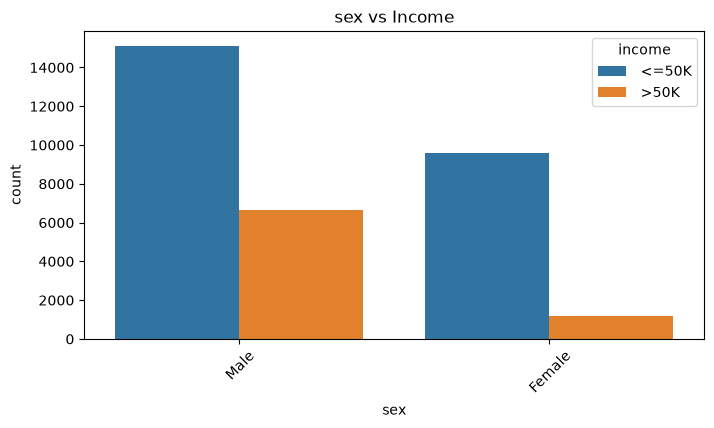

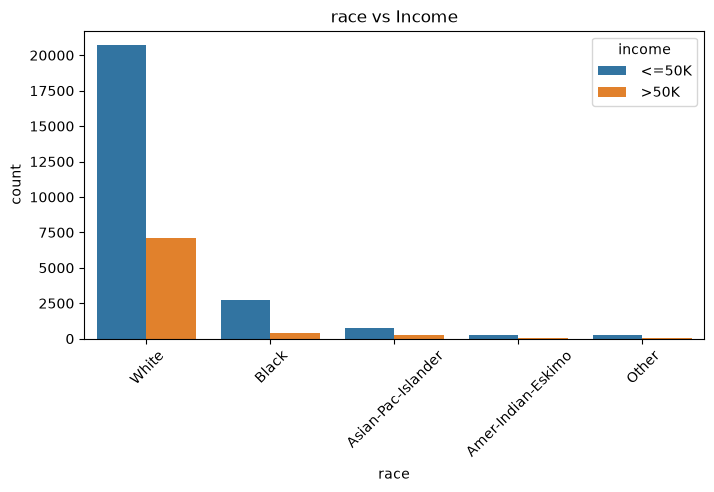

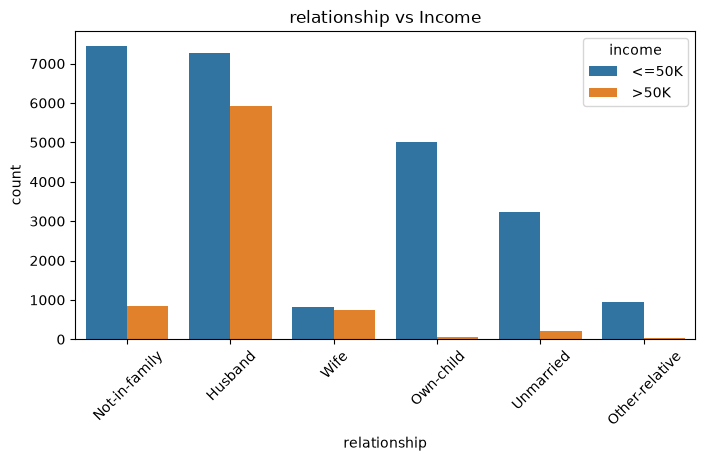

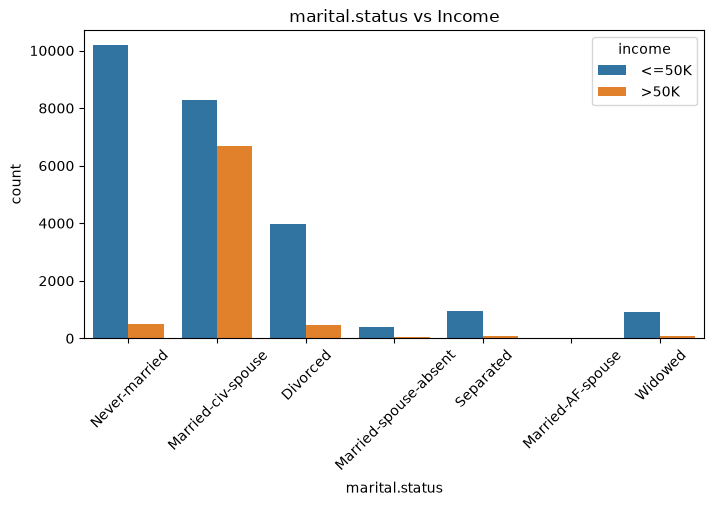

In [18]:
cat_cols = ["workclass", "education", "marital.status", "occupation",
            "relationship", "race", "sex", "native.country"]

for col in ["sex", "race", "relationship", "marital.status"]:
    plt.figure(figsize=(8,4))
    sns.countplot(x=col, hue="income", data=df)
    plt.xticks(rotation=45)
    plt.title(f"{col} vs Income")
    plt.show()

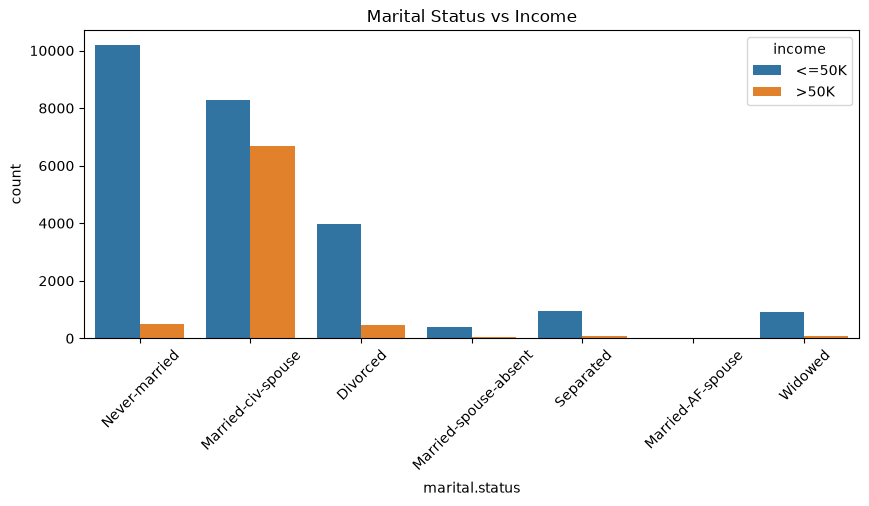

In [19]:
plt.figure(figsize=(10,4))
sns.countplot(x="marital.status", hue="income", data=df)
plt.xticks(rotation=45)
plt.title("Marital Status vs Income")
plt.show()

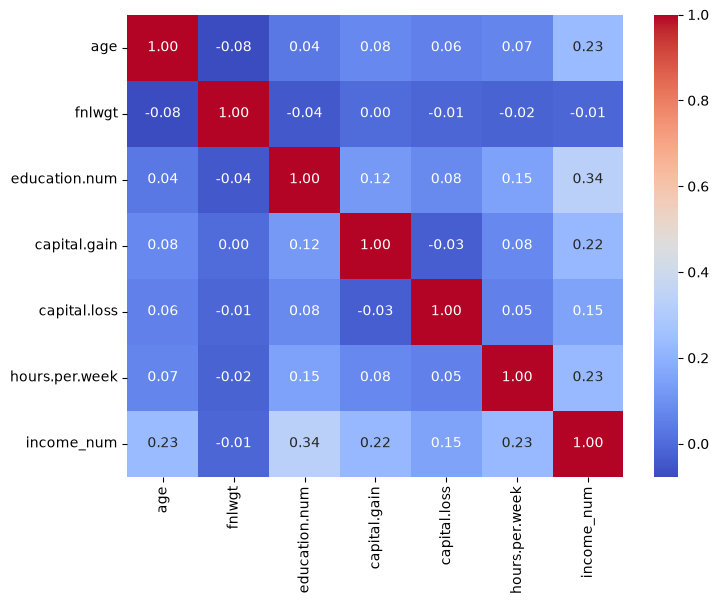

In [72]:
df_corr = df.copy()
df_corr["income_num"] = (df_corr["income"] == " >50K").astype(int)
plt.figure(figsize=(8,6))
sns.heatmap(df_corr[num_cols + ["income_num"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

### DATA CLEANING

In [21]:
df.drop_duplicates(inplace=True)

In [73]:
df.reset_index(drop=True,inplace=True)

In [23]:
df = df.drop(columns=["fnlwgt", "education"])
df.columns

Index(['age', 'workclass', 'education.num', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'capital.gain', 'capital.loss',
       'hours.per.week', 'native.country', 'income'],
      dtype='str')

In [24]:
cat_missing = ["workclass", "occupation", "native.country"]

imputer = SimpleImputer(strategy="most_frequent")
df[cat_missing] = imputer.fit_transform(df[cat_missing])


In [25]:
df.isnull().sum().sort_values(ascending=False)

age               0
workclass         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

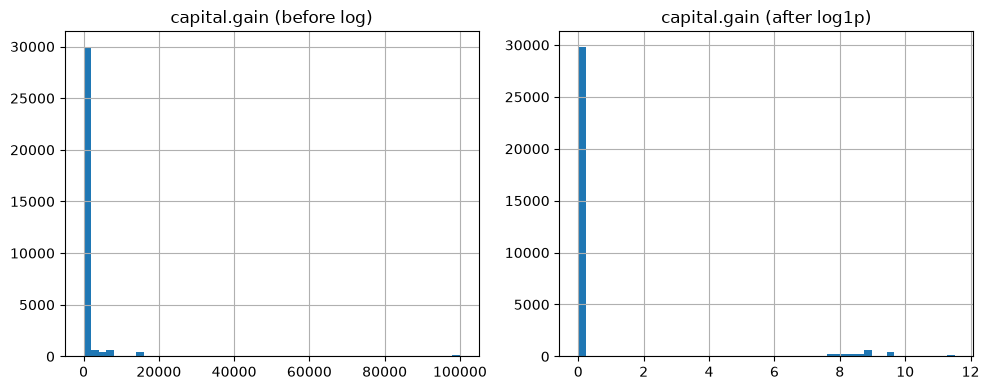

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))

df["capital.gain"].hist(bins=50, ax=axes[0])
axes[0].set_title("capital.gain (before log)")

np.log1p(df["capital.gain"]).hist(bins=50, ax=axes[1])
axes[1].set_title("capital.gain (after log1p)")

plt.tight_layout()
plt.show()

In [27]:
cols = ["age", "education.num", "hours.per.week", "capital.gain", "capital.loss"]

print("Skewness BEFORE log:")
print(df[cols].skew().round(2))

print("\nSkewness AFTER log1p:")
print(np.log1p(df[["capital.gain", "capital.loss"]]).skew().round(2))

Skewness BEFORE log:
age                0.56
education.num     -0.31
hours.per.week     0.23
capital.gain      11.95
capital.loss       4.59
dtype: float64

Skewness AFTER log1p:
capital.gain    3.09
capital.loss    4.31
dtype: float64


### ENCODING

In [28]:
print(df["income"].dtype)
print(df["income"].unique())

str
<ArrowStringArray>
[' <=50K', ' >50K']
Length: 2, dtype: str


In [29]:
str_cols = df.select_dtypes(include=["object", "string"]).columns

for col in str_cols:
    df[col] = df[col].str.strip()

print(df["income"].unique())
print(df["workclass"].unique())

<ArrowStringArray>
['<=50K', '>50K']
Length: 2, dtype: str
<ArrowStringArray>
[       'State-gov', 'Self-emp-not-inc',          'Private',
      'Federal-gov',        'Local-gov',     'Self-emp-inc',
      'Without-pay',     'Never-worked']
Length: 8, dtype: str


In [30]:
df["income"] = (df["income"] == ">50K").astype(int)

print(df["income"].value_counts())

income
0    24698
1     7839
Name: count, dtype: int64


In [31]:
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = df.select_dtypes(include="number").drop(columns="income").columns.tolist()

print("Categorical:", cat_cols)
print("Numerical:", num_cols)

Categorical: ['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']
Numerical: ['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']


In [32]:
for col in cat_cols:
    print(f"{col:18s} -> {df[col].nunique()} categories")

workclass          -> 8 categories
marital.status     -> 7 categories
occupation         -> 14 categories
relationship       -> 6 categories
race               -> 5 categories
sex                -> 2 categories
native.country     -> 41 categories


In [33]:
print(df["native.country"].value_counts().head(10))
print()
print("US percentage:", round((df["native.country"] == "United-States").mean() * 100, 1), "%")

native.country
United-States    29735
Mexico             639
Philippines        198
Germany            137
Canada             121
Puerto-Rico        114
El-Salvador        106
India              100
Cuba                95
England             90
Name: count, dtype: int64

US percentage: 91.4 %


In [34]:
df["native.country"] = df["native.country"].apply(
    lambda x: "United-States" if x == "United-States" else "Other"
)

print(df["native.country"].value_counts())

native.country
United-States    29735
Other             2802
Name: count, dtype: int64


In [35]:
pd.get_dummies(df[["sex"]]).head()

,sex_Female,sex_Male
0,False,True
1,False,True
2,False,True
3,False,True
4,True,False


In [38]:
print("Before:", df.shape)

df = pd.get_dummies(df, columns=cat_cols, dtype=int)

print("After:", df.shape)
df.head()

Before: (32537, 13)
After: (32537, 50)


,age,education.num,capital.gain,capital.loss,hours.per.week,income,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,relationship_Wife,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Female,sex_Male,native.country_Other,native.country_United-States
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,1,0,1,0,1
1,50,13,0,0,13,0,0,0,0,0,...,0,0,0,0,0,1,0,1,0,1
2,38,9,0,0,40,0,0,0,0,1,...,0,0,0,0,0,1,0,1,0,1
3,53,7,0,0,40,0,0,0,0,1,...,0,0,0,1,0,0,0,1,0,1
4,28,13,0,0,40,0,0,0,0,1,...,1,0,0,1,0,0,1,0,1,0


In [39]:
corr = df.corr()["income"].drop("income").sort_values()

print("Top 8 positive:")
print(corr.tail(8).round(2))
print("\nTop 8 negative:")
print(corr.head(8).round(2))

Top 8 positive:
occupation_Exec-managerial           0.21
sex_Male                             0.22
capital.gain                         0.22
hours.per.week                       0.23
age                                  0.23
education.num                        0.34
relationship_Husband                 0.40
marital.status_Married-civ-spouse    0.44
Name: income, dtype: float64

Top 8 negative:
marital.status_Never-married   -0.32
relationship_Own-child         -0.23
sex_Female                     -0.22
relationship_Not-in-family     -0.19
occupation_Other-service       -0.16
relationship_Unmarried         -0.14
marital.status_Divorced        -0.13
workclass_Private              -0.13
Name: income, dtype: float64


### TRAIN/TEST SPLIT

In [40]:
X = df.drop("income", axis=1)
y = df["income"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("\nTrain target %:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTest target %:")
print(y_test.value_counts(normalize=True).round(3))

Train: (26029, 49)
Test: (6508, 49)

Train target %:
income
0    0.759
1    0.241
Name: proportion, dtype: float64

Test target %:
income
0    0.759
1    0.241
Name: proportion, dtype: float64


### SCALING

In [41]:
log_cols = ["capital.gain", "capital.loss"]
scale_cols = ["age", "education.num", "hours.per.week"]

log_pipe = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    [
        ("log", log_pipe, log_cols),
        ("num", StandardScaler(), scale_cols),
    ],
    remainder="passthrough"   
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Train:", X_train_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (26029, 49)
Test: (6508, 49)


### MODELS

In [43]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Logistic Regression

Confusion Matrix:
 [[4572  368]
 [ 610  958]]


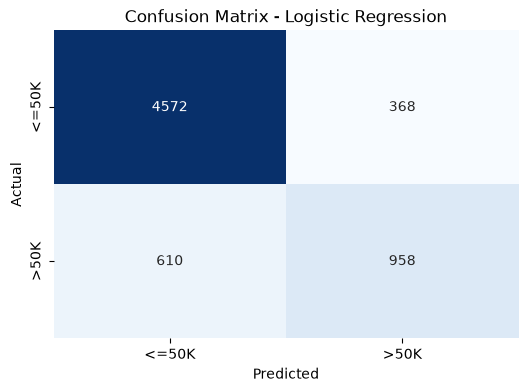


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      4940
        >50K       0.72      0.61      0.66      1568

    accuracy                           0.85      6508
   macro avg       0.80      0.77      0.78      6508
weighted avg       0.84      0.85      0.85      6508

ROC-AUC: 0.9029


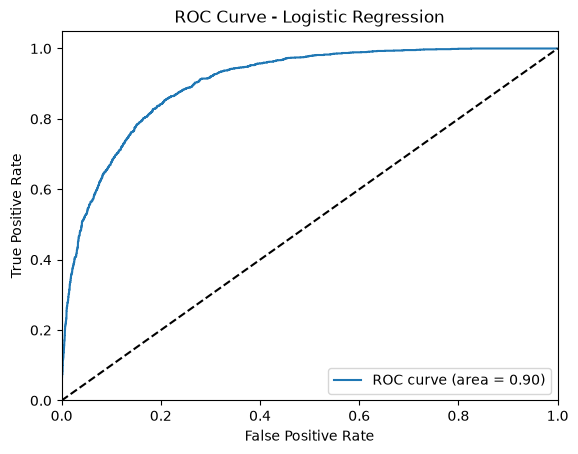

PR AUC: 0.7527


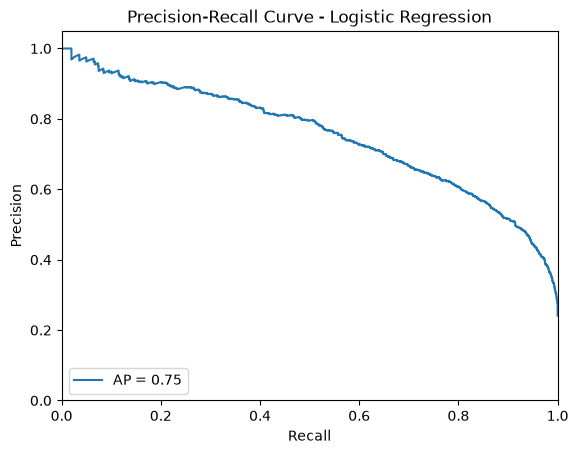

  8%|▊         | 1/13 [00:00<00:06,  1.72it/s]


KNN

Confusion Matrix:
 [[4458  482]
 [ 575  993]]


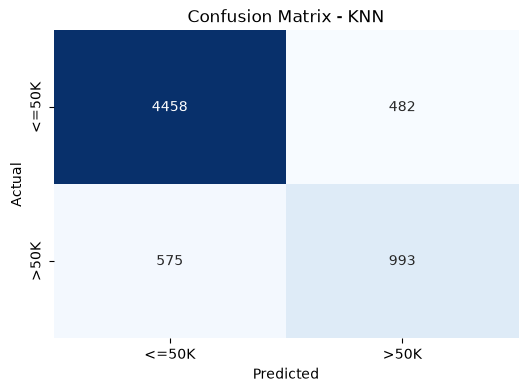


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.89      0.90      0.89      4940
        >50K       0.67      0.63      0.65      1568

    accuracy                           0.84      6508
   macro avg       0.78      0.77      0.77      6508
weighted avg       0.83      0.84      0.84      6508

ROC-AUC: 0.8668


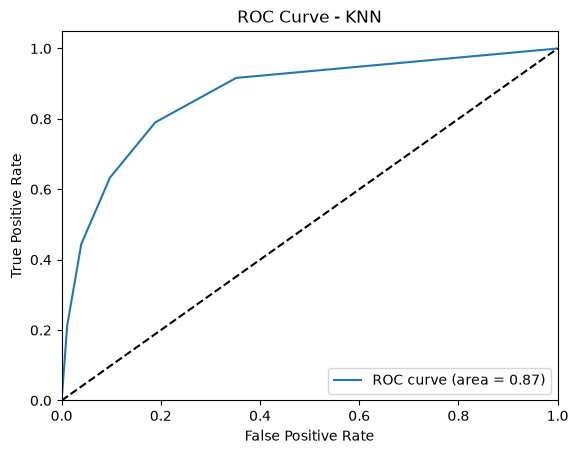

PR AUC: 0.6571


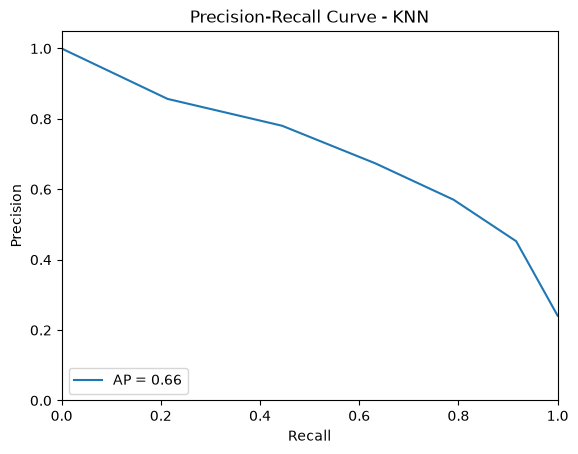

 15%|█▌        | 2/13 [00:03<00:24,  2.23s/it]


SVC


c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion Matrix:
 [[4643  297]
 [ 604  964]]


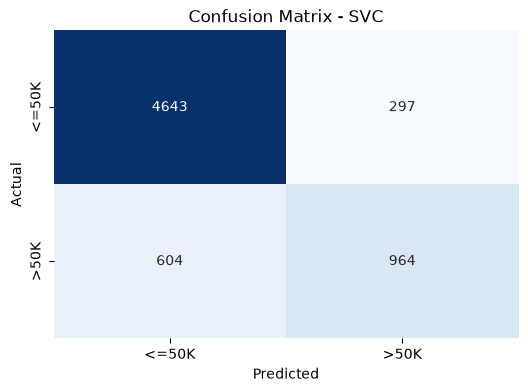


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      4940
        >50K       0.76      0.61      0.68      1568

    accuracy                           0.86      6508
   macro avg       0.82      0.78      0.80      6508
weighted avg       0.86      0.86      0.86      6508

ROC-AUC: 0.905


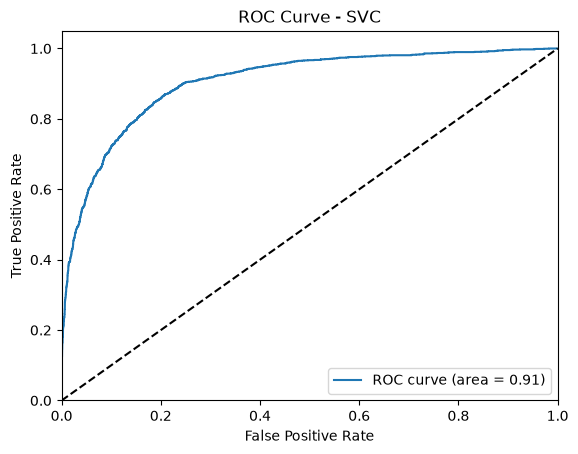

PR AUC: 0.7871


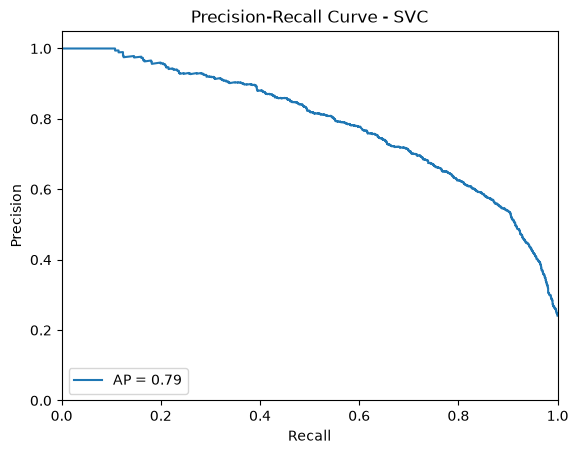

 23%|██▎       | 3/13 [04:50<22:02, 132.22s/it]


Decision Tree

Confusion Matrix:
 [[4404  536]
 [ 595  973]]


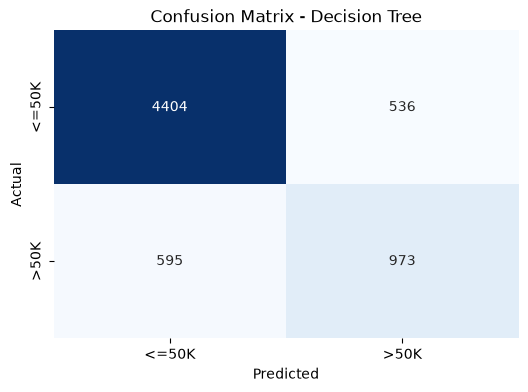


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.89      0.89      4940
        >50K       0.64      0.62      0.63      1568

    accuracy                           0.83      6508
   macro avg       0.76      0.76      0.76      6508
weighted avg       0.82      0.83      0.83      6508

ROC-AUC: 0.7761


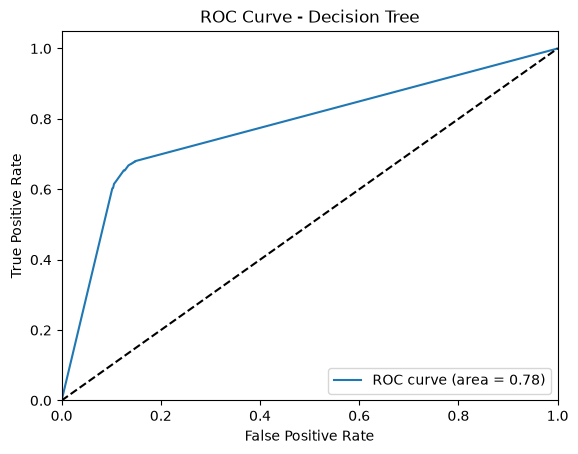

PR AUC: 0.518


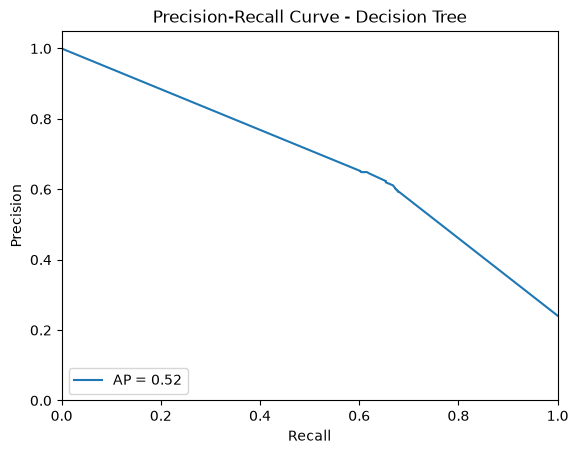

 31%|███       | 4/13 [04:51<12:01, 80.20s/it] 


Naive Bayes

Confusion Matrix:
 [[2254 2686]
 [  75 1493]]


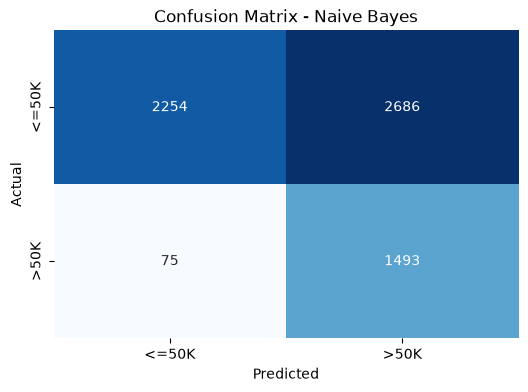


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.97      0.46      0.62      4940
        >50K       0.36      0.95      0.52      1568

    accuracy                           0.58      6508
   macro avg       0.66      0.70      0.57      6508
weighted avg       0.82      0.58      0.60      6508

ROC-AUC: 0.8592


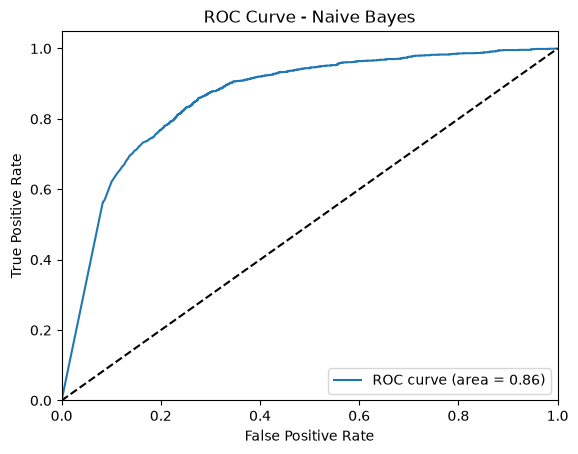

PR AUC: 0.6154


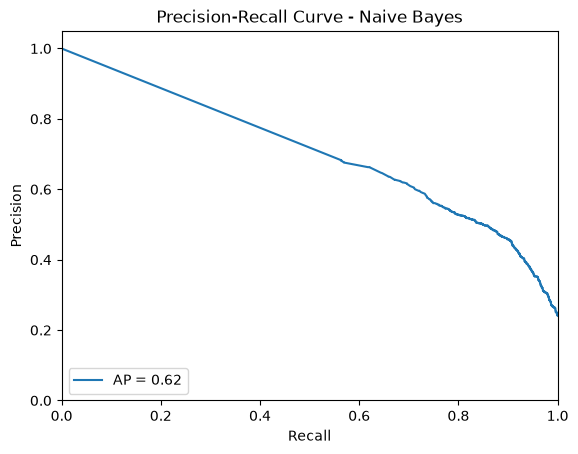

 38%|███▊      | 5/13 [04:51<06:51, 51.40s/it]


Random Forest

Confusion Matrix:
 [[4571  369]
 [ 570  998]]


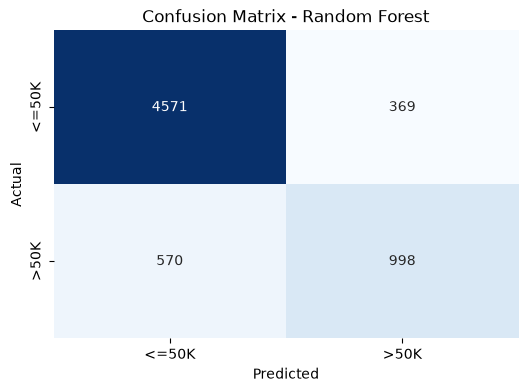


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      4940
        >50K       0.73      0.64      0.68      1568

    accuracy                           0.86      6508
   macro avg       0.81      0.78      0.79      6508
weighted avg       0.85      0.86      0.85      6508

ROC-AUC: 0.896


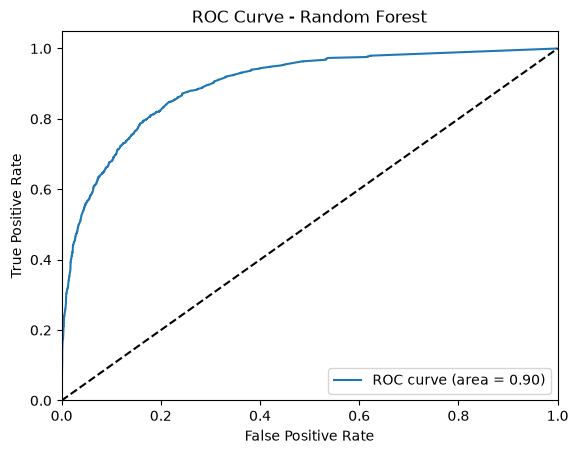

PR AUC: 0.7654


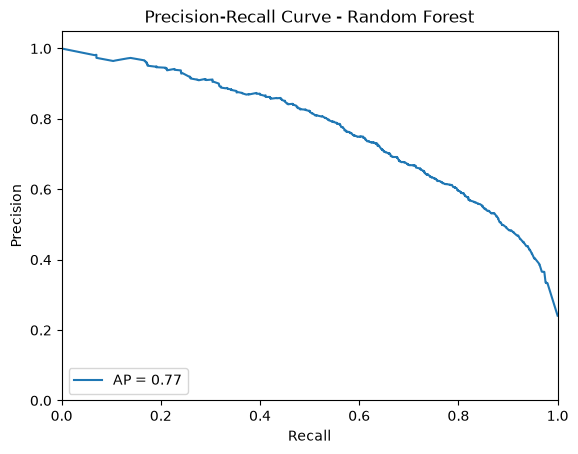

 46%|████▌     | 6/13 [04:54<04:03, 34.84s/it]


Extra Trees

Confusion Matrix:
 [[4483  457]
 [ 617  951]]


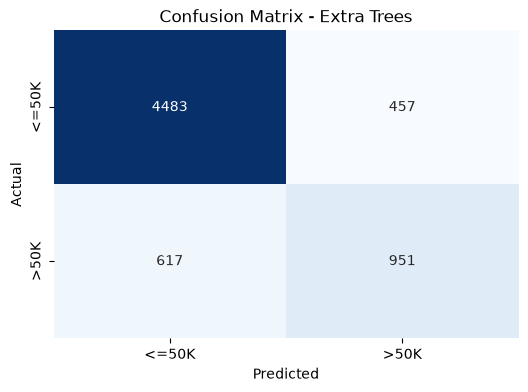


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.91      0.89      4940
        >50K       0.68      0.61      0.64      1568

    accuracy                           0.83      6508
   macro avg       0.78      0.76      0.77      6508
weighted avg       0.83      0.83      0.83      6508

ROC-AUC: 0.8536


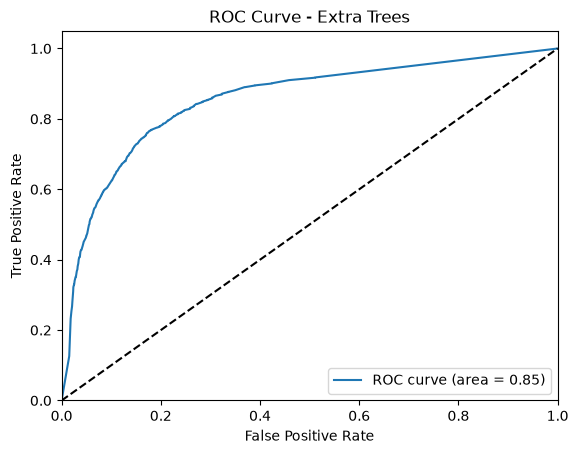

PR AUC: 0.6529


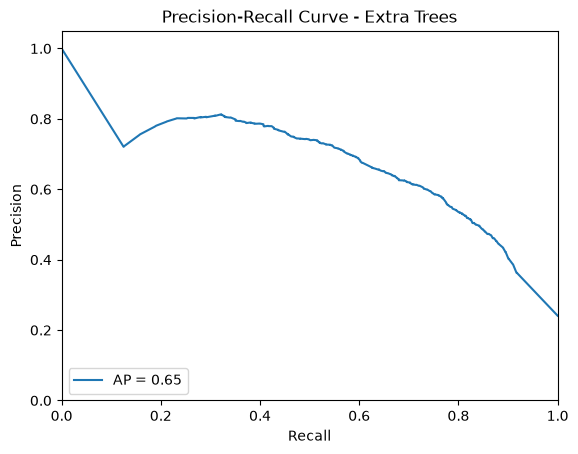

 54%|█████▍    | 7/13 [04:58<02:28, 24.67s/it]


AdaBoost

Confusion Matrix:
 [[4709  231]
 [ 699  869]]


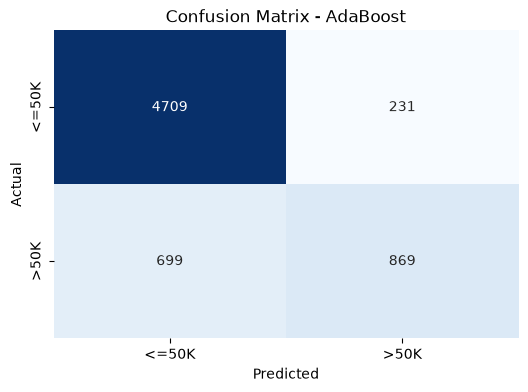


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.87      0.95      0.91      4940
        >50K       0.79      0.55      0.65      1568

    accuracy                           0.86      6508
   macro avg       0.83      0.75      0.78      6508
weighted avg       0.85      0.86      0.85      6508

ROC-AUC: 0.9078


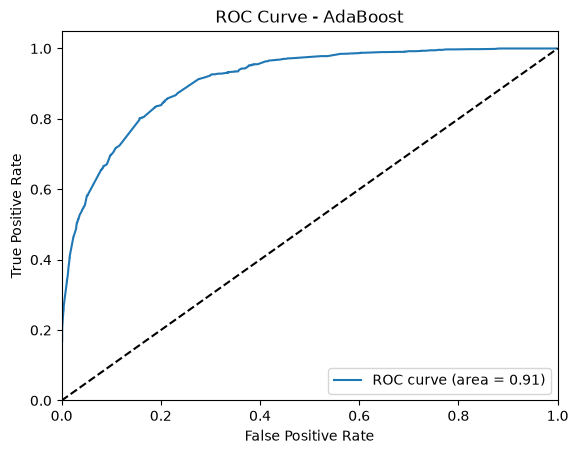

PR AUC: 0.7823


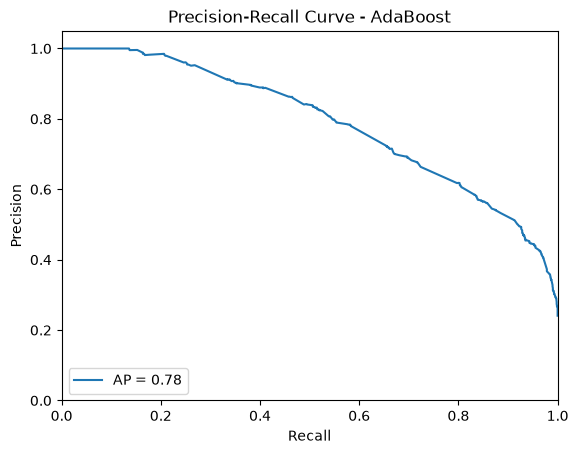

 62%|██████▏   | 8/13 [04:59<01:26, 17.22s/it]


Gradient Boosting

Confusion Matrix:
 [[4687  253]
 [ 578  990]]


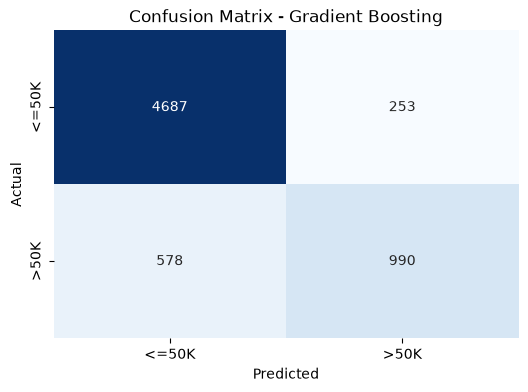


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.89      0.95      0.92      4940
        >50K       0.80      0.63      0.70      1568

    accuracy                           0.87      6508
   macro avg       0.84      0.79      0.81      6508
weighted avg       0.87      0.87      0.87      6508

ROC-AUC: 0.9273


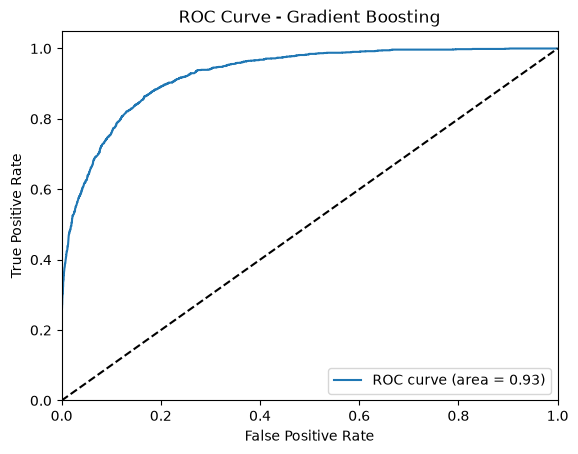

PR AUC: 0.8328


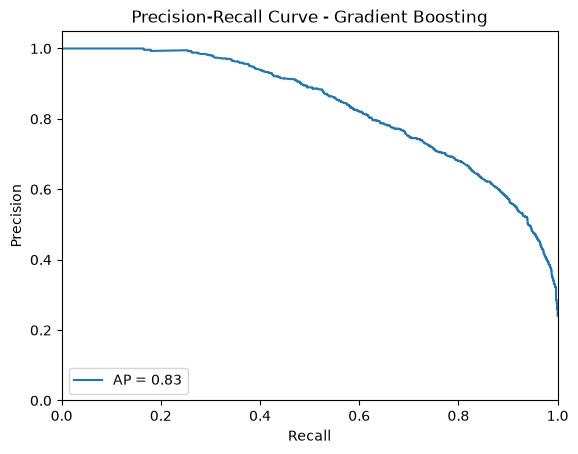

 69%|██████▉   | 9/13 [05:07<00:57, 14.43s/it]


Hist Gradient Boosting

Confusion Matrix:
 [[4648  292]
 [ 494 1074]]


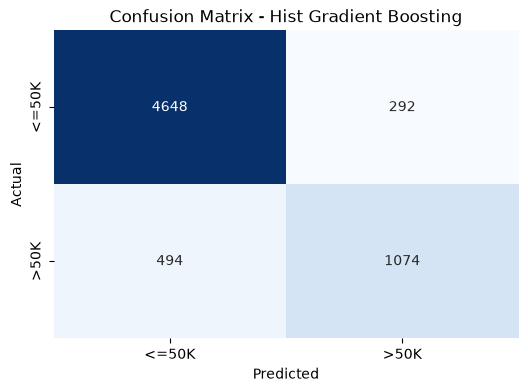


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.90      0.94      0.92      4940
        >50K       0.79      0.68      0.73      1568

    accuracy                           0.88      6508
   macro avg       0.85      0.81      0.83      6508
weighted avg       0.88      0.88      0.88      6508

ROC-AUC: 0.9327


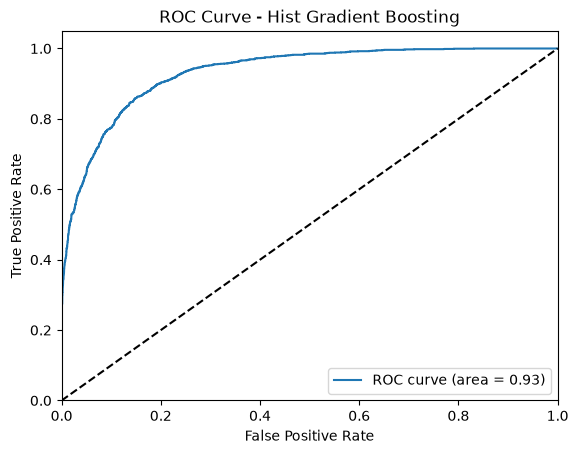

PR AUC: 0.843


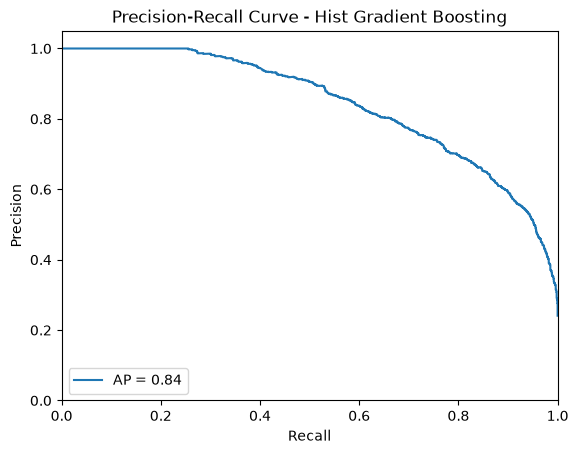

 77%|███████▋  | 10/13 [05:11<00:33, 11.02s/it]


XGBoost


c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [12:14:28] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4641  299]
 [ 488 1080]]


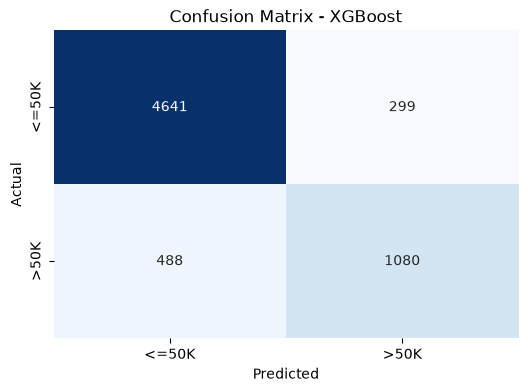


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.90      0.94      0.92      4940
        >50K       0.78      0.69      0.73      1568

    accuracy                           0.88      6508
   macro avg       0.84      0.81      0.83      6508
weighted avg       0.88      0.88      0.88      6508

ROC-AUC: 0.9316


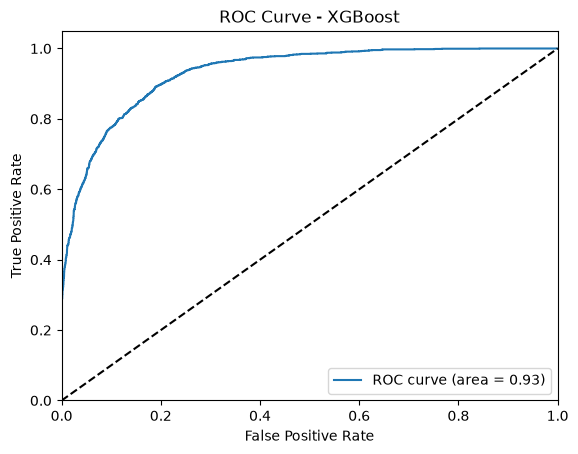

PR AUC: 0.8386


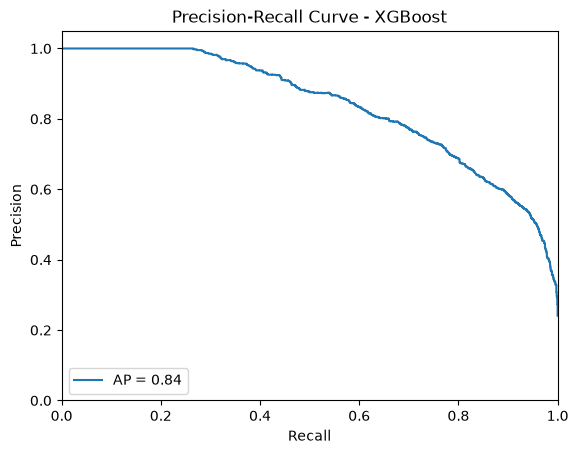

 85%|████████▍ | 11/13 [05:12<00:16,  8.16s/it]


CatBoost

Confusion Matrix:
 [[4660  280]
 [ 501 1067]]


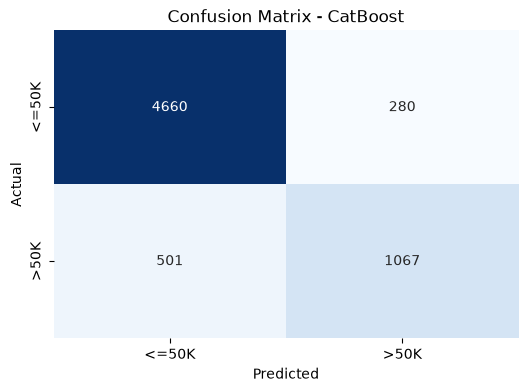


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.90      0.94      0.92      4940
        >50K       0.79      0.68      0.73      1568

    accuracy                           0.88      6508
   macro avg       0.85      0.81      0.83      6508
weighted avg       0.88      0.88      0.88      6508

ROC-AUC: 0.9332


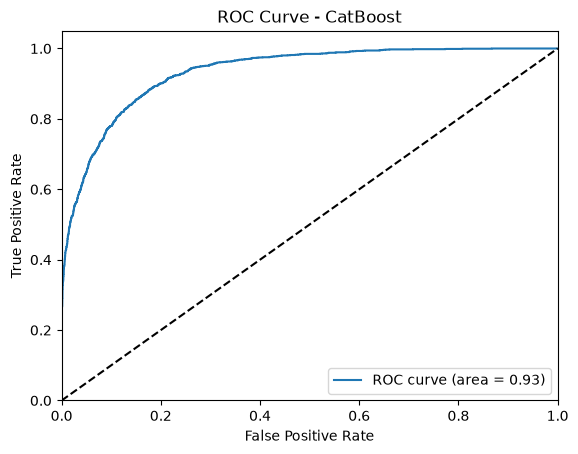

PR AUC: 0.8436


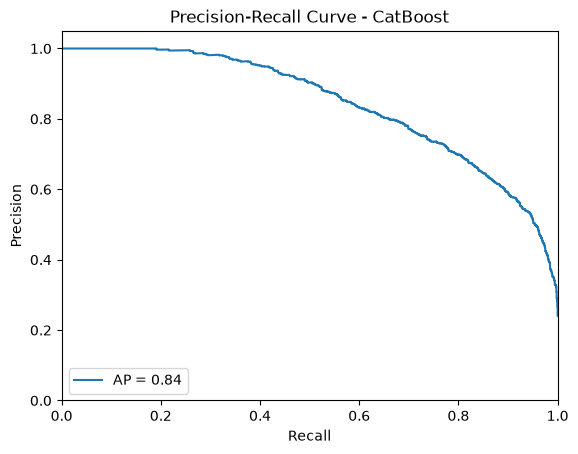

 92%|█████████▏| 12/13 [05:28<00:10, 10.37s/it]


LightGBM
[LightGBM] [Info] Number of positive: 6271, number of negative: 19758
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002934 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 418
[LightGBM] [Info] Number of data points in the train set: 26029, number of used features: 45
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.240924 -> initscore=-1.147623
[LightGBM] [Info] Start training from score -1.147623

Confusion Matrix:
 [[4660  280]
 [ 510 1058]]


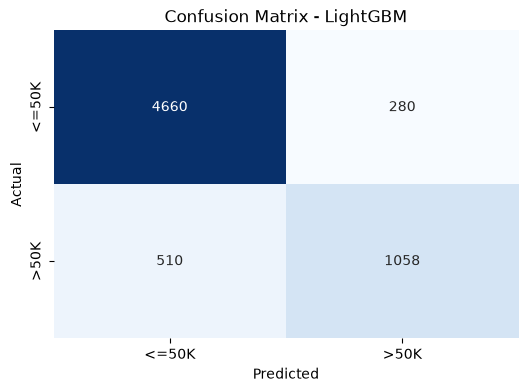


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.90      0.94      0.92      4940
        >50K       0.79      0.67      0.73      1568

    accuracy                           0.88      6508
   macro avg       0.85      0.81      0.83      6508
weighted avg       0.87      0.88      0.88      6508

ROC-AUC: 0.9326


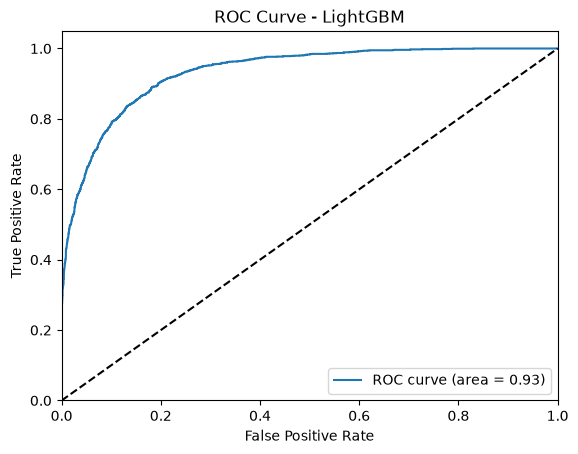

PR AUC: 0.8429


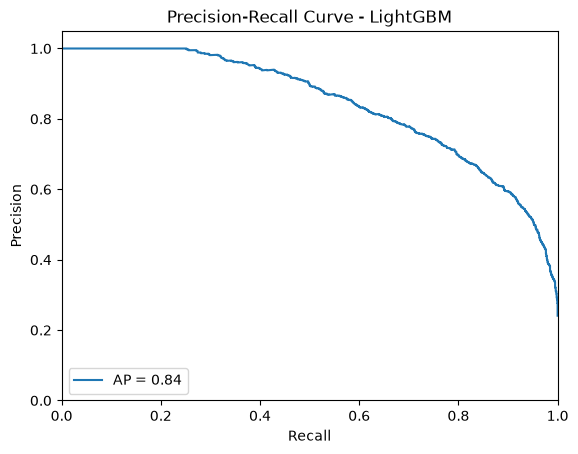

100%|██████████| 13/13 [05:29<00:00, 25.38s/it]


In [44]:
results = {}

for name, model in tqdm(models.items()):
    print("\n" + "="*60)
    print(name)
    print("="*60)

    model.fit(X_train_scaled, y_train)

    train_pred = model.predict(X_train_scaled)
    test_pred  = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["<=50K", ">50K"],
                yticklabels=["<=50K", ">50K"])
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,
                                target_names=["<=50K", ">50K"], zero_division=0))

    y_pred_prob = model.predict_proba(X_test_scaled)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", round(roc_auc, 4))

    fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label="ROC curve (area = {:.2f})".format(roc_auc))
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve - {name}")
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", round(pr_auc, 4))

    precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label="AP = {:.2f}".format(pr_auc))
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision-Recall Curve - {name}")
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc,
    }

In [45]:
results_df = pd.DataFrame(results).T
display(results_df)

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Logistic Regression,0.843252,0.849723,0.713589,0.722474,0.583639,0.610969,0.642105,0.662059,0.754645,0.768238,0.902901,0.752651
KNN,0.879327,0.837585,0.770949,0.673220,0.710094,0.633291,0.739271,0.652645,0.821567,0.767860,0.866848,0.657090
SVC,0.861078,0.861555,0.772531,0.764473,0.600064,0.614796,0.675462,0.681513,0.771993,0.777337,0.905015,0.787105
Decision Tree,0.977371,0.826214,0.984151,0.644798,0.920906,0.620536,0.951479,0.632434,0.958099,0.756017,0.776116,0.518034
Naive Bayes,0.575089,0.575753,0.356367,0.357263,0.947377,0.952168,0.517915,0.519575,0.702153,0.704222,0.859212,0.615374
Random Forest,0.977371,0.855716,0.964064,0.730066,0.941158,0.636480,0.952473,0.680068,0.965011,0.780892,0.896032,0.765449
Extra Trees,0.977371,0.834972,0.984151,0.675426,0.920906,0.606505,0.951479,0.639113,0.958099,0.756997,0.853565,0.652863
AdaBoost,0.848477,0.857099,0.772419,0.790000,0.526072,0.554209,0.625877,0.651424,0.738439,0.753724,0.907846,0.782327
Gradient Boosting,0.867648,0.872311,0.794252,0.796460,0.608196,0.631378,0.688883,0.704376,0.779096,0.790081,0.927336,0.832779
Hist Gradient Boosting,0.883515,0.879226,0.804589,0.786237,0.682188,0.684949,0.738350,0.732106,0.814801,0.812920,0.932706,0.843030


In [46]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"],
}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)
grid.fit(X_train_scaled, y_train)

print("Best params :", grid.best_params_)
print("Best CV F1  :", round(grid.best_score_, 3))

best_lr = grid.best_estimator_
print("Test F1     :", round(f1_score(y_test, best_lr.predict(X_test_scaled)), 3))

Best params : {'C': 0.1, 'class_weight': 'balanced'}
Best CV F1  : 0.67
Test F1     : 0.677


In [47]:
param_grids = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=42),
        {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]}),
    "KNN": (
        KNeighborsClassifier(),
        {"n_neighbors": [5, 11, 21], "weights": ["uniform", "distance"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {"max_depth": [3, 5, 8, 12], "min_samples_leaf": [1, 10, 30]}),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {"n_estimators": [200], "max_depth": [8, 12, None], "min_samples_leaf": [1, 5]}),
    "Extra Trees": (
        ExtraTreesClassifier(random_state=42, n_jobs=-1),
        {"n_estimators": [200], "max_depth": [8, 12, None], "min_samples_leaf": [1, 5]}),
    "AdaBoost": (
        AdaBoostClassifier(random_state=42),
        {"n_estimators": [50, 200], "learning_rate": [0.1, 0.5, 1.0]}),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]}),
    "XGBoost": (
        XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=-1),
        {"n_estimators": [200, 400], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]}),
    "LightGBM": (
        LGBMClassifier(random_state=42, verbose=-1, n_jobs=-1),
        {"n_estimators": [200, 400], "learning_rate": [0.05, 0.1], "num_leaves": [15, 31]}),
}


In [48]:
tuned = {}
rows = []

for name, (est, grid_params) in param_grids.items():
    gs = GridSearchCV(est, grid_params, scoring="f1", cv=cv, n_jobs=-1)
    gs.fit(X_train_scaled, y_train)

    best = gs.best_estimator_
    pred = best.predict(X_test_scaled)
    proba = best.predict_proba(X_test_scaled)[:, 1]
    tuned[name] = best

    rows.append({
        "Model": name,
        "best_params_": gs.best_params_,
        "best_score_ (CV F1)": round(gs.best_score_, 3),
        "Test F1": round(f1_score(y_test, pred), 3),
        "Test ROC-AUC": round(roc_auc_score(y_test, proba), 3),
        "Test PR AUC": round(average_precision_score(y_test, proba), 3),
    })

tuning_df = pd.DataFrame(rows).sort_values("Test F1", ascending=False)
tuning_df

,Model,best_params_,best_score_ (CV F1),Test F1,Test ROC-AUC,Test PR AUC
7,XGBoost,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.710,0.732,0.932,0.843
6,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.708,0.731,0.931,0.841
8,LightGBM,"{'learning_rate': 0.1, 'n_estimators': 400, 'n...",0.710,0.730,0.932,0.842
3,Random Forest,"{'max_depth': None, 'min_samples_leaf': 5, 'n_...",0.676,0.703,0.924,0.825
5,AdaBoost,"{'learning_rate': 1.0, 'n_estimators': 200}",0.655,0.686,0.917,0.806
0,Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.670,0.677,0.902,0.750
1,KNN,"{'n_neighbors': 21, 'weights': 'uniform'}",0.662,0.676,0.900,0.741
2,Decision Tree,"{'max_depth': 12, 'min_samples_leaf': 10}",0.666,0.673,0.906,0.784
4,Extra Trees,"{'max_depth': None, 'min_samples_leaf': 5, 'n_...",0.645,0.668,0.909,0.780


In [50]:
before = results_df["Test F1 Score"].rename("F1 Before Tuning")
after = tuning_df.set_index("Model")["Test F1"].rename("F1 After Tuning")

comparison = pd.concat([before, after], axis=1).dropna()
comparison["Change"] = (comparison["F1 After Tuning"] - comparison["F1 Before Tuning"]).round(3)
comparison.sort_values("F1 After Tuning", ascending=False)

,F1 Before Tuning,F1 After Tuning,Change
XGBoost,0.732949,0.732,-0.001
Gradient Boosting,0.704376,0.731,0.027
LightGBM,0.728149,0.730,0.002
Random Forest,0.680068,0.703,0.023
AdaBoost,0.651424,0.686,0.035
Logistic Regression,0.662059,0.677,0.015
KNN,0.652645,0.676,0.023
Decision Tree,0.632434,0.673,0.041
Extra Trees,0.639113,0.668,0.029


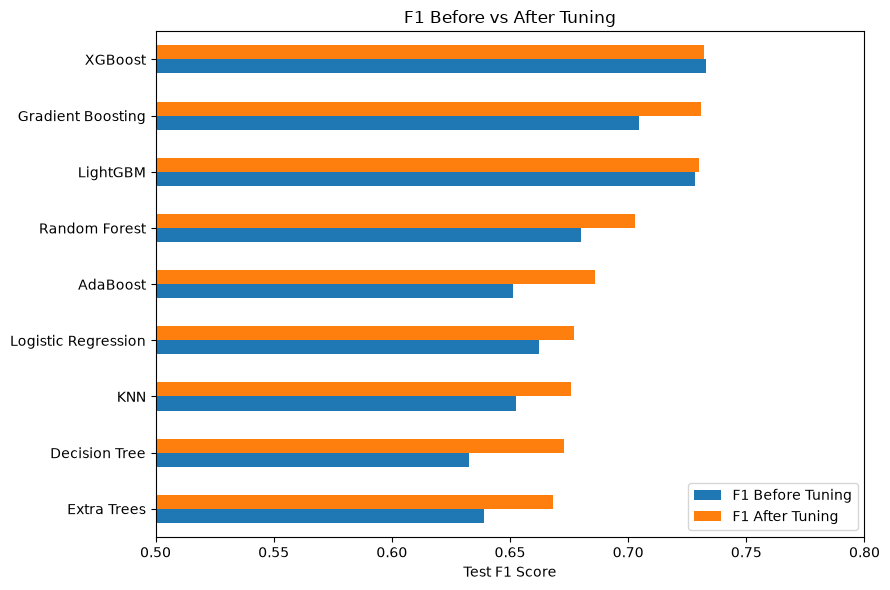

In [51]:
comparison_sorted = comparison.sort_values("F1 After Tuning")

comparison_sorted[["F1 Before Tuning", "F1 After Tuning"]].plot(
    kind="barh", figsize=(9, 6)
)
plt.xlabel("Test F1 Score")
plt.title("F1 Before vs After Tuning")
plt.xlim(0.5, 0.8)
plt.tight_layout()
plt.show()

[[4645  295]
 [ 492 1076]]


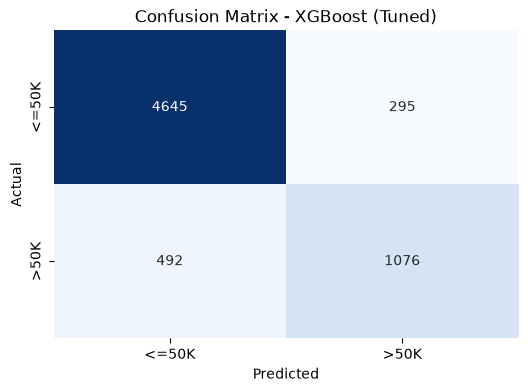

              precision    recall  f1-score   support

       <=50K       0.90      0.94      0.92      4940
        >50K       0.78      0.69      0.73      1568

    accuracy                           0.88      6508
   macro avg       0.84      0.81      0.83      6508
weighted avg       0.88      0.88      0.88      6508



In [52]:
best_model = tuned["XGBoost"]

y_pred = best_model.predict(X_test_scaled)
y_proba = best_model.predict_proba(X_test_scaled)[:, 1]

cm = confusion_matrix(y_test, y_pred)
print(cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["<=50K", ">50K"],
            yticklabels=["<=50K", ">50K"])
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.title("Confusion Matrix - XGBoost (Tuned)")
plt.show()

print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"]))

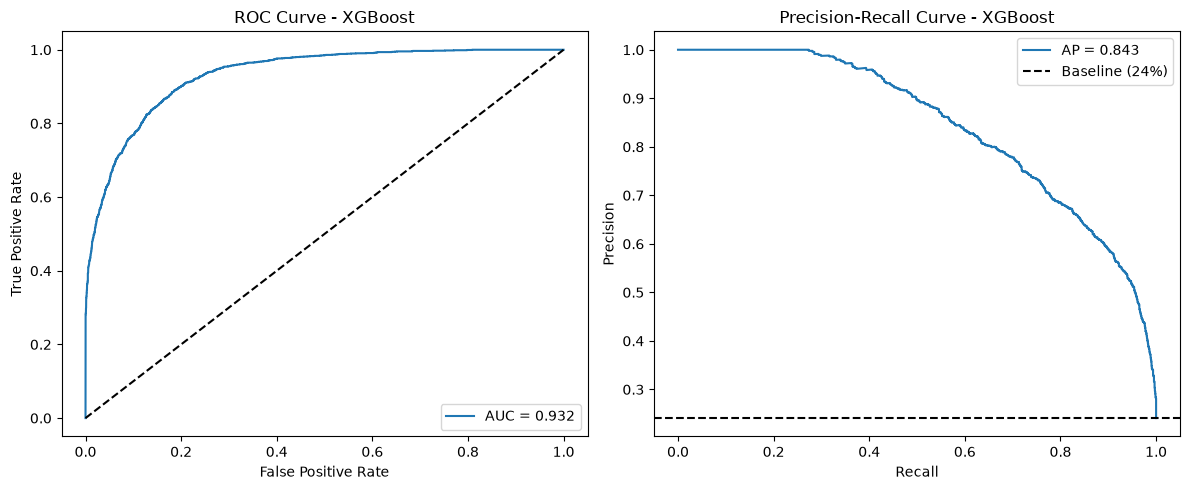

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve - XGBoost")
axes[0].legend(loc="lower right")

# Precision-Recall
prec, rec, _ = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)
axes[1].plot(rec, prec, label=f"AP = {ap:.3f}")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Baseline (24%)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve - XGBoost")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

marital.status_Married-civ-spouse    0.506
capital.gain                         0.047
education.num                        0.043
relationship_Own-child               0.034
occupation_Other-service             0.032
occupation_Exec-managerial           0.031
capital.loss                         0.023
occupation_Farming-fishing           0.018
relationship_Wife                    0.015
occupation_Tech-support              0.014
dtype: float32


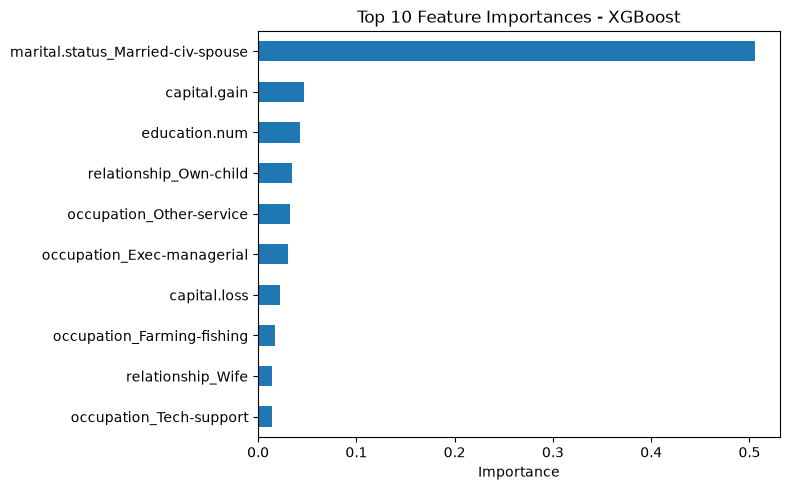

In [54]:
remaining = [c for c in X_train.columns if c not in log_cols + scale_cols]
feature_names = log_cols + scale_cols + remaining

importance = pd.Series(best_model.feature_importances_, index=feature_names)
top = importance.sort_values(ascending=False).head(10)
print(top.round(3))

top.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Feature Importances - XGBoost")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [55]:
errors = X_test.copy()
errors["actual"] = y_test.values
errors["predicted"] = y_pred

fn = errors[(errors["actual"] == 1) & (errors["predicted"] == 0)]   # missed high earners
fp = errors[(errors["actual"] == 0) & (errors["predicted"] == 1)]   # false alarms

print("False Negatives (missed >50K):", len(fn))
print("False Positives (wrongly >50K):", len(fp))

cols = ["age", "education.num", "hours.per.week", "capital.gain"]
summary = pd.DataFrame({
    "FN (missed)": fn[cols].mean(),
    "TP (caught >50K)": errors[(errors["actual"] == 1) & (errors["predicted"] == 1)][cols].mean(),
    "All >50K": errors[errors["actual"] == 1][cols].mean(),
}).round(1)
summary

False Negatives (missed >50K): 492
False Positives (wrongly >50K): 295


,FN (missed),TP (caught >50K),All >50K
age,43.0,44.9,44.3
education.num,10.1,12.3,11.6
hours.per.week,44.4,45.7,45.3
capital.gain,77.2,6220.6,4292.9


In [56]:
import joblib, json, os

os.makedirs("models", exist_ok=True)

joblib.dump(best_model, "models/xgb_model.pkl")
joblib.dump(preprocessor, "models/preprocessor.pkl")

feature_columns = X_train.columns.tolist()

cat_options = {
    col: sorted(c.replace(f"{col}_", "", 1) for c in feature_columns if c.startswith(f"{col}_"))
    for col in cat_cols
}

with open("models/feature_columns.json", "w") as f:
    json.dump(feature_columns, f)
with open("models/cat_options.json", "w") as f:
    json.dump(cat_options, f, indent=2)

print(os.listdir("models"))
print(cat_options["sex"], cat_options["native.country"])

['cat_options.json', 'feature_columns.json', 'preprocessor.pkl', 'xgb_model.pkl']
['Female', 'Male'] ['Other', 'United-States']


In [57]:
model_l = joblib.load("models/xgb_model.pkl")
prep_l = joblib.load("models/preprocessor.pkl")

# take one raw test row and predict through the loaded files
sample = X_test.iloc[[0]]
pred = model_l.predict(prep_l.transform(sample))[0]
proba = model_l.predict_proba(prep_l.transform(sample))[0, 1]

print("Predicted:", pred, "| prob >50K:", round(proba, 3), "| actual:", y_test.iloc[0])

Predicted: 0 | prob >50K: 0.013 | actual: 0
